# 1 Dataset

1.1 Extracting a Subset of the Dataset

In [9]:
import tarfile

tar_path = '/Users/mina/Desktop/Yelp-JSON/Yelp JSON/yelp_dataset.tar'
extract_path = '/Users/mina/Desktop/Yelp-JSON/Yelp JSON/yelp_dataset_extracted'

with tarfile.open(tar_path) as tar:
    tar.extractall(path=extract_path)

print("Extraction done.")


Extraction done.


In [ ]:
import pandas as pd
from collections import defaultdict


chunksize = 10_000
base_path = '/Users/mina/Desktop/Yelp-JSON/Yelp JSON/yelp_dataset_extracted'


business_df = pd.read_json(f'{base_path}/yelp_academic_dataset_business.json', lines=True)

restaurants_df = business_df[
    business_df['categories'].notnull() &
    business_df['categories'].str.contains('Restaurants', case=False, na=False)
]

restaurant_ids = set(restaurants_df['business_id'])
print(f"Total restaurants in dataset: {len(restaurant_ids)}")


restaurant_user_map = defaultdict(set)

review_file = f'{base_path}/yelp_academic_dataset_review.json'

for chunk in pd.read_json(review_file, lines=True, chunksize=chunksize):
    
    chunk = chunk[chunk['business_id'].isin(restaurant_ids)]
    
    for user_id, business_id in zip(chunk['user_id'], chunk['business_id']):
        user_restaurant_map[user_id].add(business_id)
        restaurant_user_map[business_id].add(user_id)

### Filter users who reviewed >= 100 unique restaurants
qualified_users = {user for user, bus_set in user_restaurant_map.items() if len(bus_set) >= 100}

### Filter restaurants reviewed by >= 1000 unique users
qualified_restaurants = {bus for bus, user_set in restaurant_user_map.items() if len(user_set) >= 1000}

### Extract reviews only for qualified users & restaurants (chunked)
filtered_reviews = []

for chunk in pd.read_json(review_file, lines=True, chunksize=chunksize):
    filtered_chunk = chunk[
        (chunk['user_id'].isin(qualified_users)) &
        (chunk['business_id'].isin(qualified_restaurants))
    ]
    filtered_reviews.append(filtered_chunk)

filtered_reviews_df = pd.concat(filtered_reviews, ignore_index=True)

### Final Reporting
print("\nTable 1: Records Count")
print(f"Users       : {len(qualified_users)}")
print(f"Restaurants : {len(qualified_restaurants)}")
print(f"Reviews     : {len(filtered_reviews_df)}")

Total restaurants in dataset: 52268

Table 1: Records Count
Users       : 2121
Restaurants : 296
Reviews     : 23924


1.2 Holdout

In [13]:
# Convert date column to datetime
filtered_reviews_df['date'] = pd.to_datetime(filtered_reviews_df['date'])

# Sort reviews by date (oldest first)
sorted_reviews = filtered_reviews_df.sort_values(by='date')

# Get the first 20,000 as training set
train_df = sorted_reviews.iloc[:20000]

# Remaining reviews
remaining = sorted_reviews.iloc[20000:]

# Split remaining equally
midpoint = len(remaining) // 2
val_df = remaining.iloc[:midpoint]
test_df = remaining.iloc[midpoint:]

# Summary
print("\n Holdout Summary:")
print(f"Training set:   {len(train_df)} reviews")
print(f"Validation set: {len(val_df)} reviews")
print(f"Test set:       {len(test_df)} reviews")

# Save datasets
output_path = '/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits'  # adjust if needed

# Create the output directory if it doesn't exist
import os
os.makedirs(output_path, exist_ok=True)

# Save files
train_df.to_json(f'{output_path}/train_reviews.json', orient='records', lines=True)
val_df.to_json(f'{output_path}/val_reviews.json', orient='records', lines=True)
test_df.to_json(f'{output_path}/test_reviews.json', orient='records', lines=True)

print("\nSaved train, validation, and test sets to disk.")



 Holdout Summary:
Training set:   20000 reviews
Validation set: 1962 reviews
Test set:       1962 reviews

Saved train, validation, and test sets to disk.


# 2 Introducing Word Embeddings

2.1 Training Word2vec and FastText

In [1]:
import nltk, pathlib

# Make sure the base directory exists
pathlib.Path("/Users/mina/nltk_data").mkdir(parents=True, exist_ok=True)

# Download and extract Punkt
nltk.download("punkt", download_dir="/Users/mina/nltk_data")

# Tell NLTK where to look **first**
nltk.data.path.insert(0, "/Users/mina/nltk_data")


[nltk_data] Downloading package punkt to /Users/mina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
import nltk
nltk.download('all')
import nltk
print(nltk.__version__)


In [1]:
import os
import shutil
import nltk

# Step 1: Delete the broken ZIP version
zip_path = "/Users/mina/nltk_data/tokenizers/punkt_tab.zip"
if os.path.exists(zip_path):
    os.remove(zip_path)

# Step 2: Remove leftover corrupted folder (optional but safe)
shutil.rmtree("/Users/mina/nltk_data/tokenizers/punkt_tab", ignore_errors=True)

# Step 3: Re-download 'punkt' cleanly into your local directory
nltk.download('punkt', download_dir="/Users/mina/nltk_data")

# Step 4: Tell NLTK to use that directory
nltk.data.path.insert(0, "/Users/mina/nltk_data")


[nltk_data] Downloading package punkt to /Users/mina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [4]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec, FastText
from collections import defaultdict
from IPython.display import display, HTML
import warnings

# Set up NLTK download directory and load Punkt
nltk.download('punkt', download_dir='/Users/mina/nltk_data')
nltk.data.path.append('/Users/mina/nltk_data')
warnings.filterwarnings('ignore')

# Load the training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Tokenize and lowercase the review texts
tokenized_corpus = [word_tokenize(text.lower()) for text in train_df['text']]

# Train Word2Vec model
w2v_model = Word2Vec(sentences=tokenized_corpus, seed=1234)

# Train FastText model
ft_model = FastText(sentences=tokenized_corpus, seed=1234)

# Define target words
targets = ['tasty', 'give']

# Store results
results = defaultdict(dict)

for word in targets:
    # Get similar words from FastText
    try:
        results[word]['FastText'] = [w for w, _ in ft_model.wv.most_similar(word, topn=15)]
    except KeyError:
        results[word]['FastText'] = ['<OOV>'] * 15

    # Get similar words from Word2Vec
    try:
        results[word]['Word2Vec'] = [w for w, _ in w2v_model.wv.most_similar(word, topn=15)]
    except KeyError:
        results[word]['Word2Vec'] = ['<OOV>'] * 15

# Display results in HTML table
def display_embedding_results_table(results):
    table_html = """
    <h3>Table: Top-15 Similar Words</h3>
    <table style='border-collapse: collapse; width: 100%;'>
        <tr>
            <th style='border: 1px solid black; padding: 8px;'>#</th>
            <th style='border: 1px solid black; padding: 8px;'>FastText (tasty)</th>
            <th style='border: 1px solid black; padding: 8px;'>Word2Vec (tasty)</th>
            <th style='border: 1px solid black; padding: 8px;'>FastText (give)</th>
            <th style='border: 1px solid black; padding: 8px;'>Word2Vec (give)</th>
        </tr>
    """
    for i in range(15):
        table_html += f"""
        <tr>
            <td style='border: 1px solid black; padding: 8px;'>{i+1}</td>
            <td style='border: 1px solid black; padding: 8px;'>{results['tasty']['FastText'][i]}</td>
            <td style='border: 1px solid black; padding: 8px;'>{results['tasty']['Word2Vec'][i]}</td>
            <td style='border: 1px solid black; padding: 8px;'>{results['give']['FastText'][i]}</td>
            <td style='border: 1px solid black; padding: 8px;'>{results['give']['Word2Vec'][i]}</td>
        </tr>
        """
    table_html += "</table>"
    display(HTML(table_html))

# Show the results
display_embedding_results_table(results)


[nltk_data] Downloading package punkt to /Users/mina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


#,FastText (tasty),Word2Vec (tasty),FastText (give),Word2Vec (give)
1,tasty-,yummy,forgive,allow
2,good-,delicious,gives,consider
3,delicious,good,given,bring
4,delicious-,flavorful,agave,rate
5,good,delish,ive,kill
6,flavorful,filling,gigi,warn
7,pasty,disappointing,gave,giving
8,tasteful,underwhelming,five,tell
9,goodbye,strong,ave,call
10,-good,satisfying,suave,add


# 3 The Recommender System

3.1 Implementation

In [5]:
# Part 3.1: Recommender System Implementation (Initial Version)
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import FastText
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using FastText (default: CBOW)
fasttext_model = FastText(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, fasttext_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Train regression model
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# Predict on training set
y_pred = regressor.predict(X_train)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

print(f"[FastText Model] | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:07<00:00, 2847.36it/s]


[FastText Model] | Training RMSE: 0.8213 | Training R²: 0.2590 | Regressor: LinearRegression | Embedding Aggregation Method: Mean Aggregation


In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using Word2Vec (default: CBOW)
w2v_model = Word2Vec(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, w2v_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Train regression model
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# Predict on training set
y_pred = regressor.predict(X_train)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

print(f"[Word2Vec Model] | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:05<00:00, 3794.46it/s]


[Word2Vec Model] | Training RMSE: 0.8014 | Training R²: 0.2944 | Regressor: LinearRegression | Embedding Aggregation Method: Mean Aggregation


In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using Word2Vec (default: CBOW)
w2v_model = Word2Vec(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, w2v_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Train regression model (Ridge Regression)
regressor = Ridge()
regressor.fit(X_train, y_train)

# Predict on training set
y_pred = regressor.predict(X_train)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

# Final output in one line
print(f"[Word2Vec Model] | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:05<00:00, 3996.70it/s]


[Word2Vec Model] | Training RMSE: 0.7994 | Training R²: 0.2980 | Regressor: Ridge | Embedding Aggregation Method: Mean Aggregation


In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using Word2Vec (default: CBOW)
w2v_model = Word2Vec(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, w2v_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Train regression model (Random Forest Regressor)
regressor = RandomForestRegressor(random_state=1234)
regressor.fit(X_train, y_train)

# Predict on training set
y_pred = regressor.predict(X_train)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

# Final output in one line
print(f"[Word2Vec Model] | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:05<00:00, 3959.62it/s]


[Word2Vec Model] | Training RMSE: 0.3042 | Training R²: 0.8983 | Regressor: RandomForestRegressor | Embedding Aggregation Method: Mean Aggregation


In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using Word2Vec (default: CBOW)
w2v_model = Word2Vec(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, w2v_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Train regression model (Lasso Regression)
regressor = Lasso()
regressor.fit(X_train, y_train)

# Predict on training set
y_pred = regressor.predict(X_train)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

# Final output in one line
print(f"[Word2Vec Model] | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:05<00:00, 3996.67it/s]


[Word2Vec Model] | Training RMSE: 0.9541 | Training R²: 0.0000 | Regressor: Lasso | Embedding Aggregation Method: Mean Aggregation


In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

tqdm.pandas()
# Load training set
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)

# Preprocess: tokenize and lowercase
train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# Learn word embeddings using Word2Vec (default: CBOW)
w2v_model = Word2Vec(sentences=train_df['tokens'].tolist(), seed=1234)

# Compute document embeddings via mean aggregation
def get_doc_embedding(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

train_df['doc_embedding'] = train_df['tokens'].progress_apply(lambda tokens: get_doc_embedding(tokens, w2v_model))

# Prepare features and labels
X_train = np.vstack(train_df['doc_embedding'].values)
y_train = train_df['stars'].values

# Try KNN with neighbors = 3, 5, 7
neighbors_list = [3, 5, 7, 9, 11]

for k in neighbors_list:
    regressor = KNeighborsRegressor(n_neighbors=k)
    regressor.fit(X_train, y_train)
    y_pred = regressor.predict(X_train)
    rmse = np.sqrt(mean_squared_error(y_train, y_pred))
    r2 = r2_score(y_train, y_pred)
    print(f"[Word2Vec Model] | k={k} | Training RMSE: {rmse:.4f} | Training R²: {r2:.4f} | Regressor: {regressor.__class__.__name__} | Embedding Aggregation Method: Mean Aggregation")


100%|██████████| 20000/20000 [00:05<00:00, 3835.83it/s]


[Word2Vec Model] | k=3 | Training RMSE: 0.6445 | Training R²: 0.5436 | Regressor: KNeighborsRegressor | Embedding Aggregation Method: Mean Aggregation
[Word2Vec Model] | k=5 | Training RMSE: 0.7080 | Training R²: 0.4493 | Regressor: KNeighborsRegressor | Embedding Aggregation Method: Mean Aggregation
[Word2Vec Model] | k=7 | Training RMSE: 0.7363 | Training R²: 0.4044 | Regressor: KNeighborsRegressor | Embedding Aggregation Method: Mean Aggregation
[Word2Vec Model] | k=9 | Training RMSE: 0.7543 | Training R²: 0.3749 | Regressor: KNeighborsRegressor | Embedding Aggregation Method: Mean Aggregation
[Word2Vec Model] | k=11 | Training RMSE: 0.7655 | Training R²: 0.3562 | Regressor: KNeighborsRegressor | Embedding Aggregation Method: Mean Aggregation


3.2 Hyperparameter Tuning

In [12]:
# Part 3.2: Hyperparameter Tuning with Random Forest Regressor for All 6 Embedding Configurations

import pandas as pd
import numpy as np
import nltk
import optuna
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec, FastText, Doc2Vec
from gensim.models.doc2vec import TaggedDocument
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import optuna.visualization as vis

nltk.download('punkt')
tqdm.pandas()

# Load training and validation data
train_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/train_reviews.json', lines=True)
val_df = pd.read_json('/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/val_reviews.json', lines=True)

train_df['tokens'] = train_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))
val_df['tokens'] = val_df['text'].progress_apply(lambda x: word_tokenize(x.lower()))

# All 6 configurations
CONFIGS = [
    ('word2vec', 'sg'),
    ('word2vec', 'cbow'),
    ('fasttext', 'sg'),
    ('fasttext', 'cbow'),
    ('doc2vec', 'dm'),
    ('doc2vec', 'dbow'),
]

results = {}

def objective(trial, config_name, train_df, val_df):
    model_type, mode = config_name
    vector_size = trial.suggest_int("vector_size", 50, 200)
    window = trial.suggest_int("window", 2, 10)
    min_count = trial.suggest_int("min_count", 1, 10)
    epochs = trial.suggest_int("epochs", 5, 30)

    if model_type in ['word2vec', 'fasttext']:
        sg = 1 if mode == 'sg' else 0
        sentences = train_df['tokens'].tolist()
        if model_type == 'word2vec':
            model = Word2Vec(sentences=sentences, vector_size=vector_size, window=window, 
                             min_count=min_count, sg=sg, seed=1234, epochs=epochs)
        else:
            model = FastText(sentences=sentences, vector_size=vector_size, window=window, 
                             min_count=min_count, sg=sg, seed=1234, epochs=epochs)

        def get_embedding(tokens):
            vectors = [model.wv[token] for token in tokens if token in model.wv]
            return np.mean(vectors, axis=0) if vectors else np.zeros(vector_size)

        X_train = np.vstack(train_df['tokens'].progress_apply(get_embedding))
        X_val = np.vstack(val_df['tokens'].progress_apply(get_embedding))

    else:
        dm = 1 if mode == 'dm' else 0
        tagged_docs = [TaggedDocument(words=row.tokens, tags=[str(i)]) for i, row in train_df.iterrows()]
        model = Doc2Vec(documents=tagged_docs, vector_size=vector_size, window=window,
                        min_count=min_count, dm=dm, seed=1234, epochs=epochs)

        X_train = np.vstack([model.infer_vector(row.tokens) for _, row in train_df.iterrows()])
        X_val = np.vstack([model.infer_vector(row.tokens) for _, row in val_df.iterrows()])

    y_train = train_df['stars'].values
    y_val = val_df['stars'].values

    # Normalize features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    # Random Forest Regressor hyperparameters
    n_estimators = trial.suggest_int("n_estimators", 50, 200)
    max_depth = trial.suggest_int("max_depth", 5, 30)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 10)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 4)

    model_reg = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=1234
    )
    model_reg.fit(X_train, y_train)
    y_pred = model_reg.predict(X_val)
    return r2_score(y_val, y_pred)

# Run tuning loop for all 6 configurations
for model_type, mode in CONFIGS:
    config_name = (model_type, mode)
    print(f"\nTuning: {model_type.upper()} - {mode.upper()}")

    study = optuna.create_study(direction="maximize")
    study.optimize(lambda trial: objective(trial, config_name, train_df, val_df), n_trials=20)

    print("Best R²:", study.best_value)
    print("Best Params:", study.best_params)
    results[f"{model_type}_{mode}"] = {
        'r2': study.best_value,
        'params': study.best_params,
        'study': study
    }
    

# Generate and display importance plots for all studies
for config_key, result in results.items():
    print(f"\n📊 Hyperparameter Importance: {config_key.upper()}")
    fig = vis.plot_param_importances(result['study'])
    fig.show()



[nltk_data] Downloading package punkt to /Users/mina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
100%|██████████| 1962/1962 [00:01<00:00, 1223.70it/s]
[I 2025-07-04 01:30:06,656] A new study created in memory with name: no-name-5d7bd403-2b54-4c57-ab1d-90b44f8f9ff3



Tuning: WORD2VEC - SG


100%|██████████| 1962/1962 [00:00<00:00, 4460.95it/s]
[I 2025-07-04 01:33:19,605] Trial 0 finished with value: 0.3521956285435408 and parameters: {'vector_size': 72, 'window': 4, 'min_count': 2, 'epochs': 12, 'n_estimators': 93, 'max_depth': 24, 'min_samples_split': 5, 'min_samples_leaf': 4}. Best is trial 0 with value: 0.3521956285435408.
100%|██████████| 1962/1962 [00:00<00:00, 4291.41it/s]
[I 2025-07-04 01:44:43,372] Trial 1 finished with value: 0.37067631456169703 and parameters: {'vector_size': 131, 'window': 8, 'min_count': 9, 'epochs': 21, 'n_estimators': 177, 'max_depth': 21, 'min_samples_split': 6, 'min_samples_leaf': 3}. Best is trial 1 with value: 0.37067631456169703.
100%|██████████| 1962/1962 [00:00<00:00, 4187.95it/s]
[I 2025-07-04 01:53:00,971] Trial 2 finished with value: 0.3589356580764761 and parameters: {'vector_size': 139, 'window': 9, 'min_count': 4, 'epochs': 26, 'n_estimators': 52, 'max_depth': 23, 'min_samples_split': 2, 'min_samples_leaf': 4}. Best is trial 1 w

Best R²: 0.379899187164323
Best Params: {'vector_size': 117, 'window': 10, 'min_count': 7, 'epochs': 5, 'n_estimators': 186, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 4}

Tuning: WORD2VEC - CBOW


100%|██████████| 1962/1962 [00:00<00:00, 4388.15it/s]
[I 2025-07-04 04:02:18,856] Trial 0 finished with value: 0.3096229668472036 and parameters: {'vector_size': 66, 'window': 5, 'min_count': 5, 'epochs': 6, 'n_estimators': 153, 'max_depth': 15, 'min_samples_split': 6, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.3096229668472036.
100%|██████████| 1962/1962 [00:00<00:00, 4394.68it/s]
[I 2025-07-04 04:11:11,931] Trial 1 finished with value: 0.34004682062657665 and parameters: {'vector_size': 147, 'window': 10, 'min_count': 6, 'epochs': 17, 'n_estimators': 189, 'max_depth': 12, 'min_samples_split': 6, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.34004682062657665.
100%|██████████| 1962/1962 [00:00<00:00, 4157.32it/s]
[I 2025-07-04 04:18:45,988] Trial 2 finished with value: 0.33247641089473245 and parameters: {'vector_size': 190, 'window': 9, 'min_count': 4, 'epochs': 10, 'n_estimators': 109, 'max_depth': 20, 'min_samples_split': 9, 'min_samples_leaf': 3}. Best is trial 

...

[I 2025-07-04 12:25:07,430] Trial 0 finished with value: 0.25618581889690606 and parameters: {'vector_size': 184, 'window': 2, 'min_count': 5, 'epochs': 17, 'n_estimators': 166, 'max_depth': 29, 'min_samples_split': 6, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.25618581889690606.
[I 2025-07-04 12:32:47,066] Trial 1 finished with value: 0.25952549184323626 and parameters: {'vector_size': 101, 'window': 3, 'min_count': 3, 'epochs': 21, 'n_estimators': 139, 'max_depth': 28, 'min_samples_split': 9, 'min_samples_leaf': 1}. Best is trial 1 with value: 0.25952549184323626.
[I 2025-07-04 12:45:42,739] Trial 2 finished with value: 0.21088701723184144 and parameters: {'vector_size': 199, 'window': 6, 'min_count': 10, 'epochs': 14, 'n_estimators': 159, 'max_depth': 22, 'min_samples_split': 8, 'min_samples_leaf': 1}. Best is trial 1 with value: 0.25952549184323626.
[I 2025-07-04 12:53:40,113] Trial 3 finished with value: 0.24283045618323884 and parameters: {'vector_size': 129, 'window':

Best R²: 0.30320078978956955
Best Params: {'vector_size': 126, 'window': 2, 'min_count': 8, 'epochs': 27, 'n_estimators': 179, 'max_depth': 26, 'min_samples_split': 5, 'min_samples_leaf': 1}

Tuning: DOC2VEC - DBOW


[I 2025-07-04 15:08:34,332] Trial 0 finished with value: 0.36071420454023717 and parameters: {'vector_size': 63, 'window': 2, 'min_count': 8, 'epochs': 28, 'n_estimators': 139, 'max_depth': 15, 'min_samples_split': 9, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.36071420454023717.
[I 2025-07-04 15:11:50,446] Trial 1 finished with value: 0.30306697486437695 and parameters: {'vector_size': 97, 'window': 8, 'min_count': 1, 'epochs': 10, 'n_estimators': 92, 'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.36071420454023717.
[I 2025-07-04 15:16:57,804] Trial 2 finished with value: 0.33649832460803475 and parameters: {'vector_size': 81, 'window': 4, 'min_count': 1, 'epochs': 18, 'n_estimators': 170, 'max_depth': 9, 'min_samples_split': 9, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.36071420454023717.
[I 2025-07-04 15:22:55,090] Trial 3 finished with value: 0.3352994025331033 and parameters: {'vector_size': 131, 'window': 5, 'min

Best R²: 0.39502883381861986
Best Params: {'vector_size': 50, 'window': 2, 'min_count': 7, 'epochs': 21, 'n_estimators': 54, 'max_depth': 30, 'min_samples_split': 7, 'min_samples_leaf': 4}

📊 Hyperparameter Importance: WORD2VEC_SG


ImportError: Tried to import 'plotly' but failed. Please make sure that the package is installed correctly to use this feature. Actual error: No module named 'plotly'.

# 4 Evaluation

[nltk_data] Downloading package punkt to /Users/mina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
100%|██████████| 1962/1962 [00:01<00:00, 1031.28it/s]



🚀 Training and evaluating WORD2VEC-SG model...

📊 WORD2VEC-SG Evaluation Results:

TRAIN:
RMSE: 0.3784
MAE: 0.2925
MAPE: 9.5979
R²: 0.8427
CCC: 0.8940
Pearson r: 0.9538

VAL:
RMSE: 0.7578
MAE: 0.6018
MAPE: 19.6129
R²: 0.3851
CCC: 0.5139
Pearson r: 0.6404

TEST:
RMSE: 0.7385
MAE: 0.5995
MAPE: 18.5851
R²: 0.4125
CCC: 0.5448
Pearson r: 0.6803

📊 Ranking Evaluation (Test User):
NDCG@1: 1.0000
NDCG@3: 1.0000
NDCG@5: 1.0000
NDCG@10: 1.0000
Spearman ρ: 0.3015
Kendall τ: 0.2500

🚀 Training and evaluating WORD2VEC-CBOW model...

📊 WORD2VEC-CBOW Evaluation Results:

TRAIN:
RMSE: 0.4044
MAE: 0.3088
MAPE: 10.2991
R²: 0.8204
CCC: 0.8763
Pearson r: 0.9461

VAL:
RMSE: 0.7836
MAE: 0.6173
MAPE: 20.1729
R²: 0.3425
CCC: 0.4775
Pearson r: 0.6091

TEST:
RMSE: 0.7717
MAE: 0.6227
MAPE: 19.3800
R²: 0.3585
CCC: 0.5023
Pearson r: 0.6391

📊 Ranking Evaluation (Test User):
NDCG@1: 1.0000
NDCG@3: 1.0000
NDCG@5: 1.0000
NDCG@10: 1.0000
Spearman ρ: 0.3015
Kendall τ: 0.2500

🚀 Training and evaluating FASTTEXT-SG mode

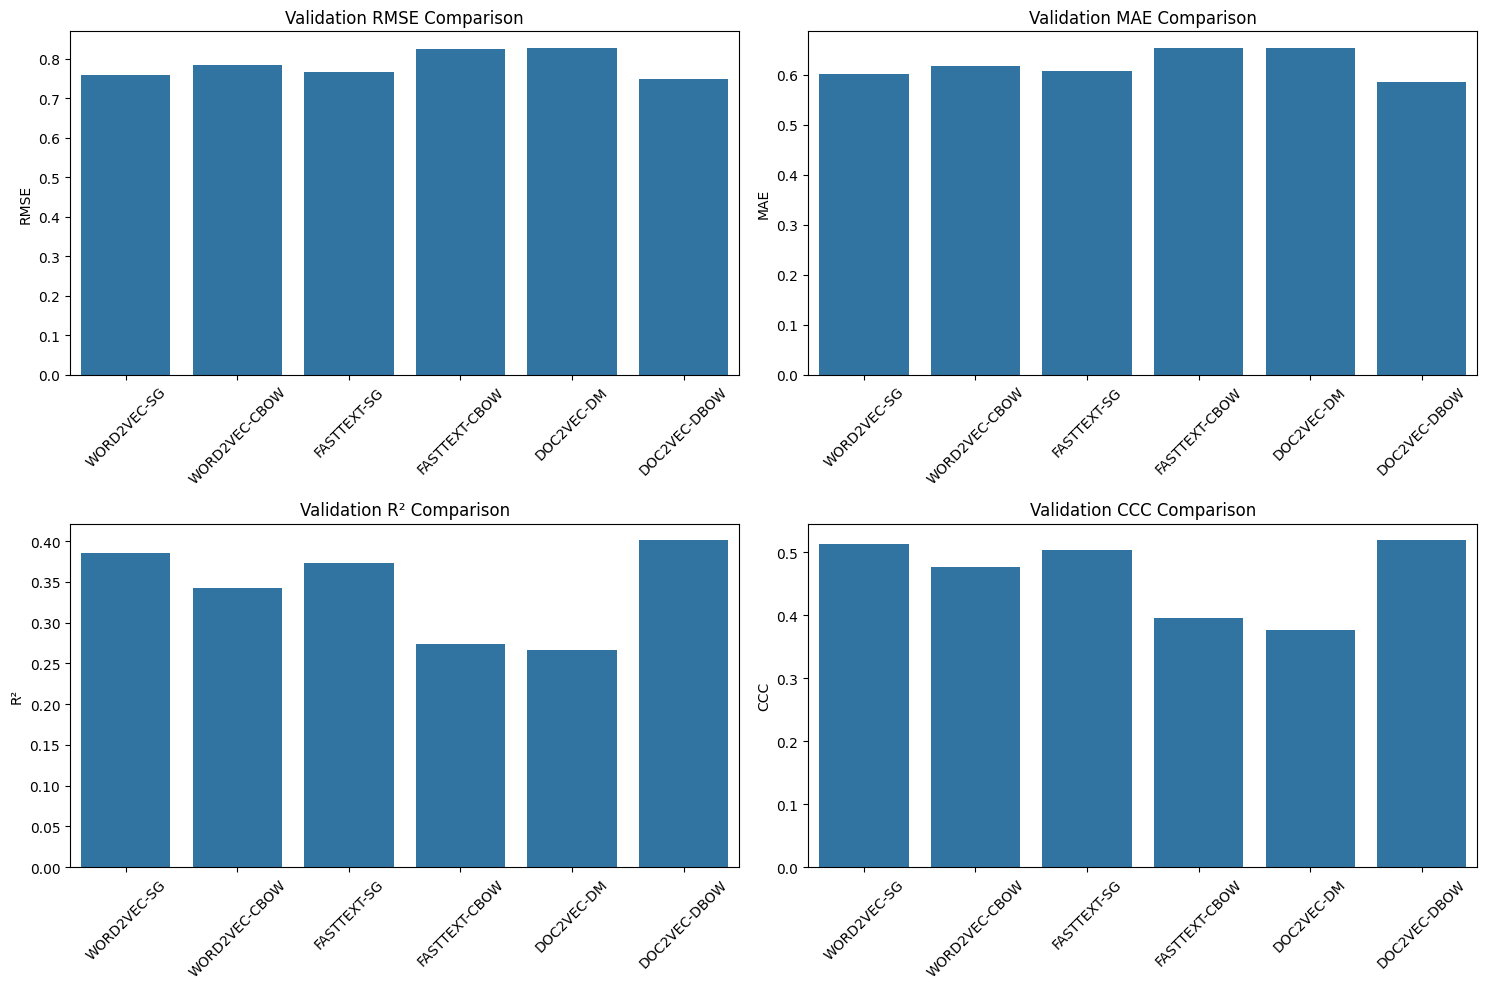

In [7]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec, FastText, Doc2Vec
from gensim.models.doc2vec import TaggedDocument
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import spearmanr, kendalltau, pearsonr
import torch
import torchmetrics
from tqdm import tqdm
import os
from torchmetrics.functional.retrieval.ndcg import retrieval_normalized_dcg
import matplotlib.pyplot as plt
import seaborn as sns

nltk.download('punkt')
tqdm.pandas()

# Helper: Concordance Correlation Coefficient (CCC)
def concordance_ccc(y_true, y_pred):
    y_true_mean = np.mean(y_true)
    y_pred_mean = np.mean(y_pred)
    covariance = np.mean((y_true - y_true_mean) * (y_pred - y_pred_mean))
    y_true_var = np.var(y_true)
    y_pred_var = np.var(y_pred)
    return (2 * covariance) / (y_true_var + y_pred_var + (y_true_mean - y_pred_mean) ** 2)

# Load splits
splits = ['train', 'val', 'test']
data = {}
for split in splits:
    path = f'/Users/mina/Desktop/Yelp-JSON/Yelp JSON/processed_splits/{split}_reviews.json'
    df = pd.read_json(path, lines=True)
    df['tokens'] = df['text'].progress_apply(lambda x: word_tokenize(x.lower()))
    data[split] = df

# Define all models with their best parameters
models_config = [
    {
        'name': 'WORD2VEC-SG',
        'type': 'word2vec',
        'params': {
            'vector_size': 117, 'window': 10, 'min_count': 7, 'epochs': 5,
            'sg': 1,  # Skip-gram
            'n_estimators': 186, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 4
        }
    },
    {
        'name': 'WORD2VEC-CBOW',
        'type': 'word2vec',
        'params': {
            'vector_size': 66, 'window': 10, 'min_count': 1, 'epochs': 25,
            'sg': 0,  # CBOW
            'n_estimators': 90, 'max_depth': 30, 'min_samples_split': 6, 'min_samples_leaf': 4
        }
    },
    {
        'name': 'FASTTEXT-SG',
        'type': 'fasttext',
        'params': {
            'vector_size': 53, 'window': 7, 'min_count': 2, 'epochs': 14,
            'sg': 1,  # Skip-gram
            'n_estimators': 193, 'max_depth': 27, 'min_samples_split': 3, 'min_samples_leaf': 4
        }
    },
    {
        'name': 'FASTTEXT-CBOW',
        'type': 'fasttext',
        'params': {
            'vector_size': 197, 'window': 7, 'min_count': 7, 'epochs': 23,
            'sg': 0,  # CBOW
            'n_estimators': 144, 'max_depth': 11, 'min_samples_split': 7, 'min_samples_leaf': 3
        }
    },
    {
        'name': 'DOC2VEC-DM',
        'type': 'doc2vec',
        'params': {
            'vector_size': 126, 'window': 2, 'min_count': 8, 'epochs': 27,
            'dm': 1,  # Distributed Memory
            'n_estimators': 179, 'max_depth': 26, 'min_samples_split': 5, 'min_samples_leaf': 1
        }
    },
    {
        'name': 'DOC2VEC-DBOW',
        'type': 'doc2vec',
        'params': {
            'vector_size': 50, 'window': 2, 'min_count': 7, 'epochs': 21,
            'dm': 0,  # DBOW
            'n_estimators': 54, 'max_depth': 30, 'min_samples_split': 7, 'min_samples_leaf': 4
        }
    }
]

# Store all results
all_results = {}
best_model = None
best_r2 = -float('inf')

# Evaluate each model
for config in models_config:
    model_name = config['name']
    print(f"\n🚀 Training and evaluating {model_name} model...")
    
    # Train embedding model
    if config['type'] == 'word2vec':
        model = Word2Vec(
            sentences=data['train']['tokens'],
            vector_size=config['params']['vector_size'],
            window=config['params']['window'],
            min_count=config['params']['min_count'],
            epochs=config['params']['epochs'],
            sg=config['params']['sg'],
            seed=1234
        )
        
        # Function to get document vector by averaging word vectors
        def get_doc_vector(tokens):
            vectors = [model.wv[word] for word in tokens if word in model.wv]
            if len(vectors) > 0:
                return np.mean(vectors, axis=0)
            return np.zeros(config['params']['vector_size'])
            
        # Infer vectors for all splits
        X = {}
        for split in splits:
            X[split] = np.vstack([get_doc_vector(row.tokens) for _, row in data[split].iterrows()])
            
    elif config['type'] == 'fasttext':
        model = FastText(
            sentences=data['train']['tokens'],
            vector_size=config['params']['vector_size'],
            window=config['params']['window'],
            min_count=config['params']['min_count'],
            epochs=config['params']['epochs'],
            sg=config['params']['sg'],
            seed=1234
        )
        
        # Function to get document vector by averaging word vectors
        def get_doc_vector(tokens):
            vectors = [model.wv[word] for word in tokens if word in model.wv]
            if len(vectors) > 0:
                return np.mean(vectors, axis=0)
            return np.zeros(config['params']['vector_size'])
            
        # Infer vectors for all splits
        X = {}
        for split in splits:
            X[split] = np.vstack([get_doc_vector(row.tokens) for _, row in data[split].iterrows()])
            
    elif config['type'] == 'doc2vec':
        tagged_docs = [TaggedDocument(words=row.tokens, tags=[str(i)]) for i, row in data['train'].iterrows()]
        model = Doc2Vec(
            documents=tagged_docs,
            vector_size=config['params']['vector_size'],
            window=config['params']['window'],
            min_count=config['params']['min_count'],
            dm=config['params']['dm'],
            seed=1234,
            epochs=config['params']['epochs']
        )
        
        # Infer vectors for all splits
        X = {}
        for split in splits:
            X[split] = np.vstack([model.infer_vector(row.tokens) for _, row in data[split].iterrows()])
    
    y = {split: data[split]['stars'].values for split in splits}
    
    # Normalize features
    scaler = StandardScaler()
    X['train'] = scaler.fit_transform(X['train'])
    X['val'] = scaler.transform(X['val'])
    X['test'] = scaler.transform(X['test'])
    
    # Train regressor
    reg = RandomForestRegressor(
        n_estimators=config['params']['n_estimators'],
        max_depth=config['params']['max_depth'],
        min_samples_split=config['params']['min_samples_split'],
        min_samples_leaf=config['params']['min_samples_leaf'],
        random_state=1234
    )
    reg.fit(X['train'], y['train'])
    
    # Store metrics for all splits
    results = {}
    for split in splits:
        y_true = y[split]
        y_pred = reg.predict(X[split])

        # Regression Error Metrics
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)
        mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

        # Goodness-of-Fit Metrics
        r2 = r2_score(y_true, y_pred)
        ccc = concordance_ccc(y_true, y_pred)
        pearson, _ = pearsonr(y_true, y_pred)

        results[split] = {
            'RMSE': rmse, 'MAE': mae, 'MAPE': mape,
            'R²': r2, 'CCC': ccc, 'Pearson r': pearson
        }
    
    # Ranking Metrics for a user in test set
    user_counts = data['test']['user_id'].value_counts()
    target_user_id = user_counts[user_counts >= 10].index[0]
    user_df = data['test'][data['test']['user_id'] == target_user_id].copy()
    user_df['predicted'] = reg.predict(scaler.transform([model.infer_vector(tokens) if config['type'] == 'doc2vec' else get_doc_vector(tokens) for tokens in user_df['tokens']]))

    # Compute IR metrics for k = 1, 3, 5, 10
    ks = [1, 3, 5, 10]
    y_true_ranked = user_df['stars'].values.reshape(1, -1)
    y_score_ranked = user_df['predicted'].values.reshape(1, -1)
    ndcg_scores = {
        f'NDCG@{k}': retrieval_normalized_dcg(
            torch.tensor(y_score_ranked, dtype=torch.float),
            torch.tensor(y_true_ranked, dtype=torch.long),
            top_k=k
        ).item()
        for k in ks
    }
    spearman, _ = spearmanr(user_df['stars'], user_df['predicted'])
    kendall, _ = kendalltau(user_df['stars'], user_df['predicted'])
    
    # Add ranking metrics to results
    results['ranking'] = {
        **ndcg_scores,
        'Spearman ρ': spearman,
        'Kendall τ': kendall
    }
    
    # Store all results
    all_results[model_name] = {
        'results': results,
        'model': model,
        'regressor': reg,
        'scaler': scaler
    }
    
    # Check if this is the best model so far (based on validation R²)
    if results['val']['R²'] > best_r2:
        best_r2 = results['val']['R²']
        best_model = model_name
    
    # Print results for this model
    print(f"\n📊 {model_name} Evaluation Results:")
    for split in splits:
        print(f"\n{split.upper()}:")
        for metric, val in results[split].items():
            print(f"{metric}: {val:.4f}")
    print("\n📊 Ranking Evaluation (Test User):")
    for k, v in results['ranking'].items():
        print(f"{k}: {v:.4f}")

# Print best model
print(f"\n🏆 Best Model: {best_model} with validation R²: {all_results[best_model]['results']['val']['R²']:.4f}")

# Visualization: Compare models' performance
metrics = ['RMSE', 'MAE', 'R²', 'CCC']
val_results = {model: all_results[model]['results']['val'] for model in all_results}

# Create comparison plots
plt.figure(figsize=(15, 10))
for i, metric in enumerate(metrics):
    plt.subplot(2, 2, i+1)
    values = [val_results[model][metric] for model in val_results]
    sns.barplot(x=list(val_results.keys()), y=values)
    plt.title(f'Validation {metric} Comparison')
    plt.xticks(rotation=45)
    plt.ylabel(metric)
plt.tight_layout()
plt.show()


In [6]:
# For the best model, show top-10 recommendations
print(f"\n🌟 Top-10 Recommendations from Best Model ({best_model}):")

# Find a user with sufficient reviews (fallback to test user if Tashalee not found)
try:
    user_df = data['val'][data['val']['user_id'] == 'Tashalee'].copy()
    if len(user_df) == 0:
        raise KeyError("Tashalee not found")
except:
    user_counts = data['val']['user_id'].value_counts()
    target_user_id = user_counts[user_counts >= 10].index[0]
    user_df = data['val'][data['val']['user_id'] == target_user_id].copy()
    print(f"User Tashalee not found. Showing recommendations for user {target_user_id} instead.")

# Get predictions (same as before)
if models_config[[i for i, m in enumerate(models_config) if m['name'] == best_model][0]]['type'] == 'doc2vec':
    user_df['predicted'] = best_config['regressor'].predict(
        best_config['scaler'].transform([best_config['model'].infer_vector(tokens) for tokens in user_df['tokens']]))
else:
    user_df['predicted'] = best_config['regressor'].predict(
        best_config['scaler'].transform([get_doc_vector(tokens) for tokens in user_df['tokens']]))

# Get top 10 recommendations - now with column existence check
top_10 = user_df.sort_values('predicted', ascending=False).head(10)

print("\nRestaurant Recommendations:")
for i, (_, row) in enumerate(top_10.iterrows(), 1):
    # Check which identifier columns exist
    restaurant_identifier = row.get('name', 
                                  row.get('business_id', 
                                         f"Business_{row.name}"))  # Fallback to index if no IDs exist
    
    print(f"{i}. {restaurant_identifier} (Predicted: {row['predicted']:.2f}, Actual: {row['stars']})")


🌟 Top-10 Recommendations from Best Model (DOC2VEC-DBOW):
User Tashalee not found. Showing recommendations for user CmR9s-2zH20UkmUt5Qwqnw instead.

Restaurant Recommendations:
1. 6_T2xzR74JqGCTPefAD8Tw (Predicted: 4.14, Actual: 5)
2. poviu-6n3iaRE4gdQz6OYw (Predicted: 4.12, Actual: 3)
3. eCikDKFbaeYVNdCD2beX0Q (Predicted: 3.97, Actual: 4)
4. S8ZFYEgMejpChID8tzKo9A (Predicted: 3.97, Actual: 5)
5. Dv6RfXLYe1atjgz3Xf4GGw (Predicted: 3.91, Actual: 4)
6. qISf5ojuYbD9h71NumGUQA (Predicted: 3.82, Actual: 5)
7. WxB8498ejPtHE7wFa89_fA (Predicted: 3.80, Actual: 3)
8. GoYSJ-YY-YwbxdgasHuq-Q (Predicted: 3.78, Actual: 4)
9. AGlh4ZDv6jnoiYfz7At9mw (Predicted: 3.72, Actual: 4)
10. ctHjyadbDQAtUFfkcAFEHw (Predicted: 3.66, Actual: 4)
